Data shape: (20640, 8) (20640, 1)
Training shape: (16512, 8) (16512, 1)
Test shape: (4128, 8) (4128, 1)


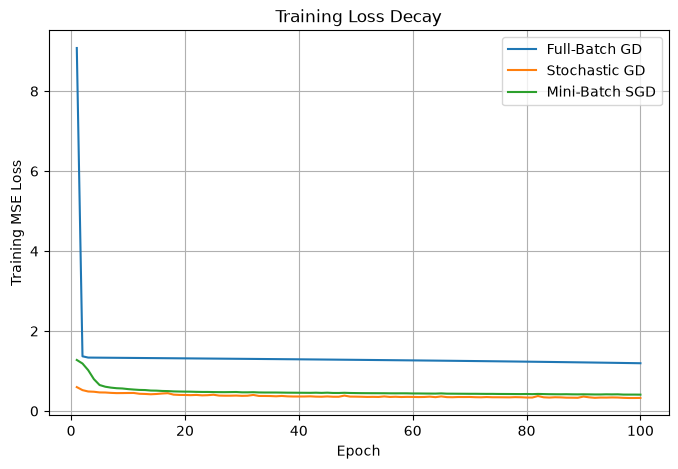

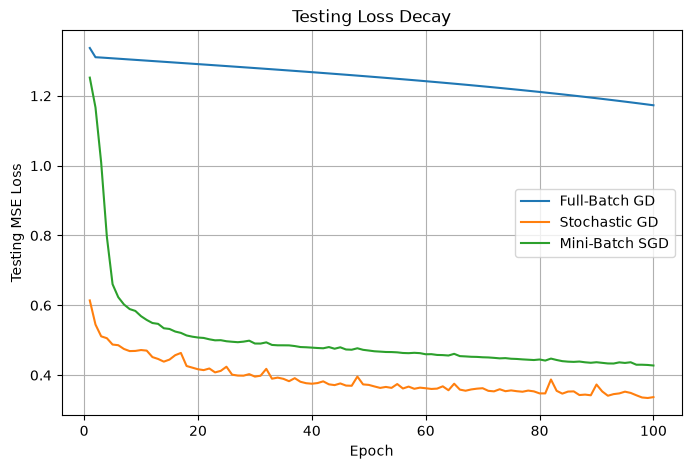

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import fetch_california_housing
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# 1. Load the data
housing = fetch_california_housing()
X, y = housing.data, housing.target.reshape(-1, 1)
print("Data shape:", X.shape, y.shape)

# 2. Split into train/test
#######################
# You implement
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training shape:", X_train.shape, y_train.shape)
print("Test shape:", X_test.shape, y_test.shape)
#######################

# 3. Fit scalers on train, transform both
#######################
# You implement
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
#######################

# 4. To tensors & datasets
#######################
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
#######################

# 5. Model factory
def get_model(n_in):
    return nn.Sequential(
      nn.Linear(n_in, 64), nn.Sigmoid(),
      nn.Linear(64, 32),   nn.Sigmoid(),
      nn.Linear(32, 1)
      )

# 6. Train and Test with Different Optimizer
#######################
def train_model(model, optimizer, x_train, y_train, x_test, y_test, epochs,
                use_minibatch=False, batch_size=64):
    criterion = nn.MSELoss()
    train_losses = []
    test_losses = []

    if use_minibatch:
        # Create dataset and DataLoader for mini-batch / SGD updates.
        dataset = TensorDataset(x_train, y_train)
        dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)
        for epoch in range(epochs):
            model.train()
            for xb, yb in dataloader:
                optimizer.zero_grad()
                preds = model(xb)
                loss = criterion(preds, yb)
                loss.backward()
                optimizer.step()

            # Evaluate loss on the full train/test sets after each epoch.
            model.eval()
            with torch.no_grad():
                train_loss = criterion(model(x_train), y_train).item()
                test_loss = criterion(model(x_test), y_test).item()
            train_losses.append(train_loss)
            test_losses.append(test_loss)
    else:
        # Full-batch update.
        for epoch in range(epochs):
            model.train()
            optimizer.zero_grad()
            preds = model(x_train)
            loss = criterion(preds, y_train)
            loss.backward()
            optimizer.step()

            model.eval()
            with torch.no_grad():
                train_loss = loss.item()
                test_loss = criterion(model(x_test), y_test).item()
            train_losses.append(train_loss)
            test_losses.append(test_loss)

    return {"train": train_losses, "test": test_losses}


def run_one_setup(epochs):
    errors = {}
    n_in = X_train_tensor.shape[1]

    # -------------------------------
    # 1. Gradient Descent (GD) - Full Batch
    # -------------------------------
    torch.manual_seed(42)
    model = get_model(n_in)
    optimizer_gd = torch.optim.SGD(model.parameters(), lr=0.05)  # full batch
    errors["Full-Batch GD"] = train_model(
        model, optimizer_gd, X_train_tensor, y_train_tensor,
        X_test_tensor, y_test_tensor, epochs, use_minibatch=False
    )

    # -------------------------------
    # 2. Stochastic Gradient Descent (SGD) - one sample per update
    # -------------------------------
    torch.manual_seed(42)
    model = get_model(n_in)
    optimizer_sgd = torch.optim.SGD(model.parameters(), lr=0.001)  # using one sample
    errors["Stochastic GD"] = train_model(
        model, optimizer_sgd, X_train_tensor, y_train_tensor,
        X_test_tensor, y_test_tensor, epochs, use_minibatch=True, batch_size=1
    )

    # -------------------------------
    # 3. Mini-Batch Stochastic Gradient Descent (SGD)
    # -------------------------------
    torch.manual_seed(42)
    model = get_model(n_in)
    optimizer_minibatch = torch.optim.SGD(model.parameters(), lr=0.01)  # using mini-batches
    errors["Mini-Batch SGD"] = train_model(
        model, optimizer_minibatch, X_train_tensor, y_train_tensor,
        X_test_tensor, y_test_tensor, epochs, use_minibatch=True, batch_size=64
    )

    return errors

# Stochastic GD performs many updates and can take longer than the other methods.
epochs = 100
errors = run_one_setup(epochs)
#######################

# 7. Plot training/testing loss decay
#######################
epoch_numbers = range(1, epochs + 1)

plt.figure(figsize=(8, 5))
plt.plot(epoch_numbers, errors["Full-Batch GD"]["train"], label="Full-Batch GD")
plt.plot(epoch_numbers, errors["Stochastic GD"]["train"], label="Stochastic GD")
plt.plot(epoch_numbers, errors["Mini-Batch SGD"]["train"], label="Mini-Batch SGD")
plt.xlabel("Epoch")
plt.ylabel("Training MSE Loss")
plt.title("Training Loss Decay")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epoch_numbers, errors["Full-Batch GD"]["test"], label="Full-Batch GD")
plt.plot(epoch_numbers, errors["Stochastic GD"]["test"], label="Stochastic GD")
plt.plot(epoch_numbers, errors["Mini-Batch SGD"]["test"], label="Mini-Batch SGD")
plt.xlabel("Epoch")
plt.ylabel("Testing MSE Loss")
plt.title("Testing Loss Decay")
plt.legend()
plt.grid(True)
plt.show()
#######################

# Step 3 and Step 4

## Step 3: Stopping criterion
Stopping criterion are either after a fixed number of iterations (100 epochs), or earlier if the parameters stop changing by a meaningful amount. In the plots, that second case is when the training MSE curve flattens. This is reasonable because gradient descent keeps stepping opposite the slope, and with a small enough learning rate those gradients have to shrink toward zero. Once the weights barely move, we are near a point where the gradient is about zero, so more epochs are not doing much. 

## Step 4: Convergence speed and final-solution quality

Stochastic GD converges the fastest. Its training and test MSE drop in the first few epochs and stay near 0.3–0.4, because it updates once per training example. Mini-batch SGD is close behind: the loss falls sharply over the first 10–20 epochs and then flattens just above stochastic GD

**Mini-Batch SGD.** It has the best speed/quality tradeoff: fast convergence, a good test MSE, and reasonable compute. Full-Batch GD is the choice only when a smooth, exact gradient matters more than wall-clock progress. Stochastic GD is useful as a comparison, not as the method to use in practice.
